# 02 · XGBoost on lag features

Gradient-boosted trees (300 trees, depth 4, lr 0.05) on 36 lag/rolling/calendar features from notebook 01.

**Key results**
- Validation MAE **5.80 MU** vs weekly naive 7.92 (**+26.8%**); largest gain at day 1 (4.74 vs 8.14).
- `lag_1` and `rolling_mean_7` carry ~67% of importance — the model is mostly a smart persistence forecaster.

> Paths are relative to `notebooks/`. Outputs are from the original research run; see [`data/README.md`](../data/README.md) for data that must be downloaded.

➡ Next: [03 · Walk-forward validation](03_walk_forward_validation.ipynb)

Initialize

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA = Path("../data")
features_clean = pd.read_parquet(
    DATA / "processed/gridpulse_features_v1.parquet"
)

EXCLUDE = {"origin", "target_date", "target", "split"}
FEATURE_COLS = [
    c for c in features_clean.columns if c not in EXCLUDE
]

train = features_clean.query("split == 'development'")
val = features_clean.query("split == 'validation'")
test = features_clean.query("split == 'test'")

X_train, y_train = train[FEATURE_COLS], train["target"]
X_val, y_val = val[FEATURE_COLS], val["target"]
X_test, y_test = test[FEATURE_COLS], test["target"]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (10087, 36)
Validation: (1799, 36)
Test: (3101, 36)


Train XGBoost

In [3]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    device="cpu",
    random_state=42,
    n_jobs=-1,
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

val_pred = model.predict(X_val)

mae = mean_absolute_error(y_val, val_pred)
rmse = np.sqrt(mean_squared_error(y_val, val_pred))

baseline_mae = 7.917
improvement = (baseline_mae - mae) / baseline_mae * 100

print(f"XGBoost validation MAE: {mae:.3f} MU")
print(f"XGBoost validation RMSE: {rmse:.3f} MU")
print(f"Improvement over weekly naive: {improvement:+.2f}%")

XGBoost validation MAE: 5.795 MU
XGBoost validation RMSE: 7.828 MU
Improvement over weekly naive: +26.80%


Investigate what XGBoost learned

,importance
lag_1,0.429545
rolling_mean_7,0.243636
lag_3,0.116257
lag_2,0.068578
month,0.014768
rolling_mean_28,0.012740
lag_5,0.011038
day_of_year,0.008110
lag_12,0.007688
day_of_week,0.007313


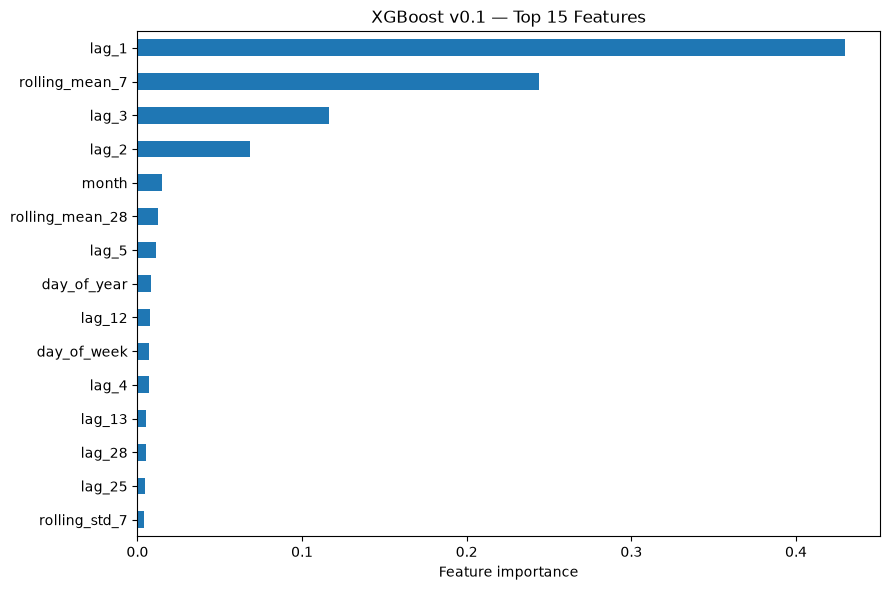

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

importance = (
    pd.Series(
        model.feature_importances_,
        index=FEATURE_COLS
    )
    .sort_values(ascending=False)
)

display(importance.head(15).to_frame("importance"))

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="XGBoost v0.1 — Top 15 Features"
)

plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

Compare validation errors

In [5]:
# Compare predictions on identical validation rows
baseline = pd.read_csv(
    DATA / "processed/seasonal_naive_predictions.csv",
    parse_dates=["origin", "target_date"],
)

comparison = val[
    ["origin", "target_date", "horizon", "target"]
].copy()

comparison["xgb_pred"] = val_pred

comparison = comparison.merge(
    baseline[
        ["origin", "target_date", "horizon", "predicted"]
    ].rename(columns={"predicted": "naive_pred"}),
    on=["origin", "target_date", "horizon"],
    validate="one_to_one",
)

comparison["xgb_error"] = (
    comparison["target"] - comparison["xgb_pred"]
).abs()

comparison["naive_error"] = (
    comparison["target"] - comparison["naive_pred"]
).abs()

by_horizon = comparison.groupby("horizon")[
    ["xgb_error", "naive_error"]
].mean()

by_horizon["improvement_pct"] = (
    100 *
    (by_horizon["naive_error"] - by_horizon["xgb_error"])
    / by_horizon["naive_error"]
)

print(by_horizon.round(3).to_string())

         xgb_error  naive_error  improvement_pct
horizon                                         
1            4.741        8.138           41.736
2            5.328        8.132           34.482
3            5.686        8.092           29.736
4            5.889        7.950           25.920
5            6.089        7.799           21.924
6            6.301        7.685           18.016
7            6.535        7.626           14.306


Monthly validation analysis

In [6]:
comparison["month"] = comparison["target_date"].dt.month

monthly = comparison.groupby("month").agg(
    xgb_mae=("xgb_error", "mean"),
    naive_mae=("naive_error", "mean"),
    observations=("target", "size"),
    total_actual=("target", "sum"),
    xgb_abs_error=("xgb_error", "sum"),
    naive_abs_error=("naive_error", "sum"),
)

monthly["xgb_wape"] = (
    100 * monthly["xgb_abs_error"]
    / monthly["total_actual"].abs()
)

monthly["naive_wape"] = (
    100 * monthly["naive_abs_error"]
    / monthly["total_actual"].abs()
)

monthly["improvement_pct"] = (
    100
    * (monthly["naive_mae"] - monthly["xgb_mae"])
    / monthly["naive_mae"]
)

print(
    monthly[
        [
            "xgb_mae",
            "naive_mae",
            "xgb_wape",
            "naive_wape",
            "improvement_pct",
            "observations",
        ]
    ].round(2).to_string()
)

       xgb_mae  naive_mae  xgb_wape  naive_wape  improvement_pct  observations
month                                                                         
1         3.43       3.86      4.72        5.31            11.08           196
2         2.08       3.21      3.12        4.84            35.41           196
3         4.58       6.11      6.26        8.35            25.03           217
4         6.42       7.81      6.34        7.72            17.78           126
5        11.73      22.26     10.44       19.80            47.28            56
6         7.70      15.54      5.76       11.64            50.46            70
7         7.91       9.42      6.60        7.86            16.07           112
8         6.33       6.73      5.31        5.65             5.99           217
9         9.47      12.28      8.26       10.71            22.85           210
10        7.05      11.11      8.98       14.14            36.53           217
11        3.14       3.90      4.61        5.73     

In [8]:
# Recreate predictions if necessary
val_pred = model.predict(X_val)

xgb_results = val[
    ["origin", "target_date", "horizon", "target"]
].copy()

xgb_results["xgb_pred"] = val_pred

xgb_results.to_parquet(
    DATA / "processed/xgb_validation_v01.parquet",
    index=False
)

print("Saved:", len(xgb_results), "predictions")

Saved: 1799 predictions
